### [GALT] Vežba 3: Raspodela zvezda u Galaksiji

### <font color='yellow'> Ideja vežbe: Određivanje Galaktičkog potencijala i rotacione krive iz sintetičke populacije zvezda. </font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod

U prošloj vežbi, generisali smo sintetičku populaciju zvezda koja prati Salpeterov zakon:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
U nastavku smo pretpostavili da su zvezde ravnomerno raspoređene u sferi, da bismo analizirali Malmkvisnovu neobjektivnost. Međutim, mi znamo da raspodela zvezda (i generalno materije) u Galaksiji nije uniformna.

Pretpostavimo da je prostorna gustina zvezda opisana eksponencijalnim diskom:

$$
\rho(R,z)=\rho_0\exp(-R/R_d)\exp(-|z|/z_d),
$$

gde su R i z cilindrične koordinate, $R_d$ i $z_d$ skala diska i visinska skala. Ugao $\varphi$ je uniforman na $(0,2\pi)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

##### <font color="green">1. Semplovati 100 000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Ovo je iz prethodne vežbe.)</font>

Najmanja masa: 0.08000068945613041 Msun
Najveca masa: 31.912932675575593 Msun
Medijana: 0.13221951871156978 Msun


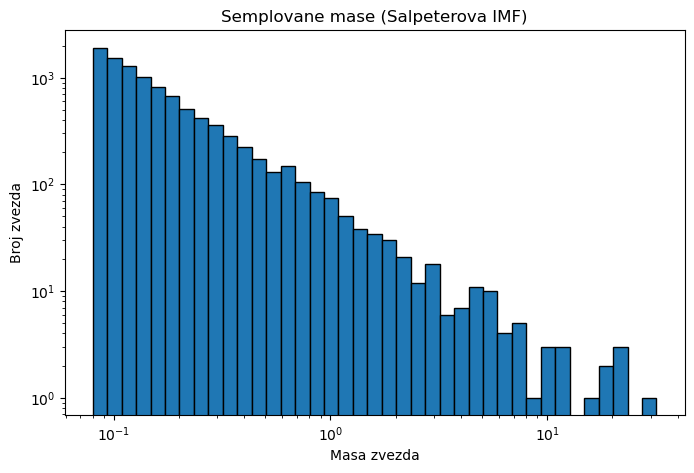

In [2]:
np.random.seed(42)                
N = 10000

alfa = 2.35
M_min, M_max = 0.08, 200.0         

u = np.random.random(N)            
a = 1 - alfa
masa = (M_min**a + u*(M_max**a - M_min**a))**(1/a)

print('Najmanja masa:', masa.min(), 'Msun')
print('Najveca masa:', masa.max(), 'Msun')
print('Medijana:', np.median(masa), 'Msun')

bins = np.logspace(np.log10(M_min), np.log10(masa.max()), 40)
plt.figure(figsize=(8, 5))
plt.hist(masa, bins=bins, edgecolor='black')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Masa zvezda')
plt.ylabel('Broj zvezda')
plt.title('Semplovane mase (Salpeterova IMF)')
plt.show()

##### <font color="green">2. Semplovati cilindrične koordinate za svaku zvezdu. (Uzeti, npr. $R_d$ = 3kpc i $z_d$ = 0.2kpc.) Objasniti kako se semplovanje vrši. </font>

In [4]:
Rd = 3.0       
zd = 0.2       

R = np.random.gamma(shape=2, scale=Rd, size=N)
phi = np.random.uniform(0, 2*np.pi, N)
z = np.random.laplace(loc=0, scale=zd, size=N)

print("Srednja radijalna udaljenost:", np.mean(R), "kpc")
print("Srednja visina:", np.mean(z), "kpc")
print("Standardna devijacija visine:", np.std(z), "kpc")

Srednja radijalna udaljenost: 6.033903848739835 kpc
Srednja visina: -0.0029909349310727044 kpc
Standardna devijacija visine: 0.2823913257485517 kpc


#### Cilindricne koordinate zvezda generisane su prema eksponencijalnom modelu galaktickog diska. Radijalna koordinata semplovana je iz gama raspodele sa parametrima k=2 i teta=R_d, jer element zapremine u cilindricnim koordinatama sadrzi faktor R. Vertikalna koordinata generisana je iz Laplasove raspodele sa centrom u z=0 i skalom z_d, dok je azimutalni ugao generisan iz uniformne raspodele na intervalu 0,2pi. Na ovaj nacin dobijena je prostorna raspodela zvezda koja odgovara zadatom eksponencijalnom disku.

##### <font color="green">3. Prikazati raspodelu zvezda u 3D, kao i (R, z) i (x, y) ravni.</font>

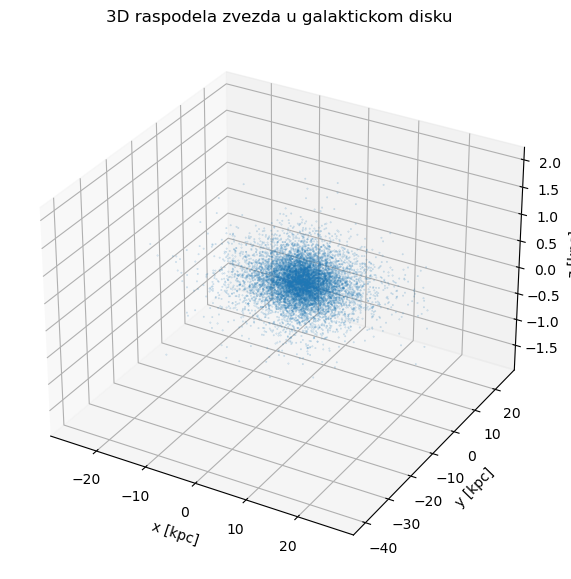

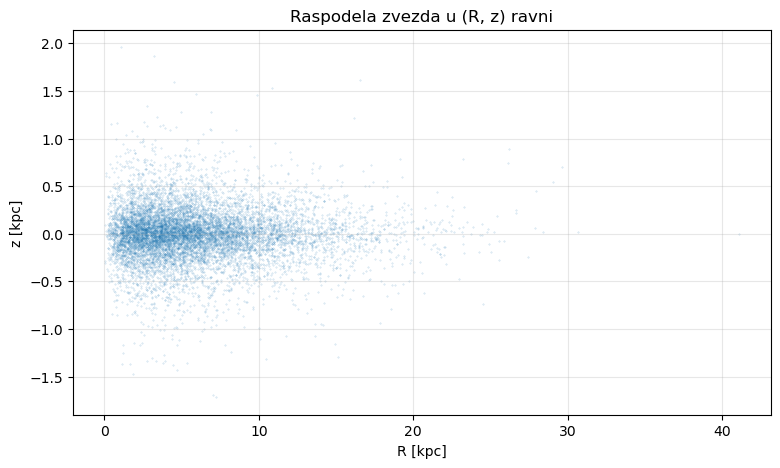

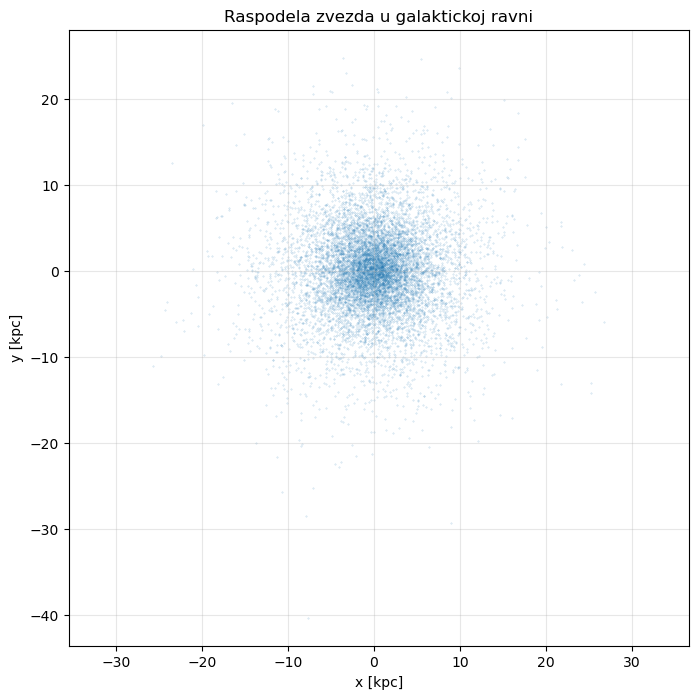

In [10]:
x = R * np.cos(phi)
y = R * np.sin(phi)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x, y, z, s=0.1, alpha=0.3)

ax.set_xlabel('x [kpc]')
ax.set_ylabel('y [kpc]')
ax.set_zlabel('z [kpc]')
ax.set_title('3D raspodela zvezda u galaktickom disku')

plt.show()

plt.figure(figsize=(9, 5))

plt.scatter(R, z, s=0.1, alpha=0.3)

plt.xlabel('R [kpc]')
plt.ylabel('z [kpc]')
plt.title('Raspodela zvezda u (R, z) ravni')
plt.grid(alpha=0.3)

plt.show()

plt.figure(figsize=(8, 8))

plt.scatter(x, y, s=0.1, alpha=0.3)

plt.xlabel('x [kpc]')
plt.ylabel('y [kpc]')
plt.title('Raspodela zvezda u galaktickoj ravni')
plt.axis('equal')
plt.grid(alpha=0.3)

plt.show()

#### Prikazana je prostorna raspodela 100.000 zvezda generisanih prema eksponencijalnom modelu galaktickog diska. Cilindricne koordinate transformisane su u Dekartove koordinate radi trodimenzionalnog prikaza. Na trodimenzionalnom grafiku uocava se spljostena struktura diska, sto je posledica znatno manje vertikalne skale u odnosu na radijalnu. U (R,z) ravni vidi se koncentracija zvezda oko galakticke ravni z=0, dok se njihov broj smanjuje sa povecanjem visine i na velikim radijalnim udaljenostima. U (x,y) ravni raspodela pokazuje pribliznu osnu simetriju, sto je u skladu sa uniformnim semplovanjem azimutalnog ugla. Povrsinska gustina zvezda najveca je u centralnom delu i eksponencijalno opada sa radijalnom udaljenoscu.

Potrebno je odraditi normalizaciju, tako da celi disk ima masu $M_{disk}$. Uzeti, npr. $M_{disk}=5\cdot 10^{10}M_\odot$. Dakle, ako integralimo prethodno zadatku gustinu po zapremini, možemo da odredimo vrednost $\rho_0$. 

##### <font color="green">4. Izračunati $\rho_0$.</font>

In [14]:
M_disk = 5e10  

rho0 = M_disk / (4 * np.pi * Rd**2 * zd)

print("Centralna gustina:", rho0, "Msun/kpc^3")
print("Centralna gustina:", rho0 / 1e9, "Msun/pc^3")

Centralna gustina: 2210485320.7207685 Msun/kpc^3
Centralna gustina: 2.2104853207207684 Msun/pc^3


#### Integracijom gustine po celoj zapremini dobijamo izraz rho0 = M_disk / (4 * pi * (Rd^2) * zd). 

Dalje, koristeći Poasonovu jednačinu: 

$$\nabla^2 \Phi = 4\pi G\rho$$

možemo da odredimo Galaktički potencijal koji odgovara zadatoj raspodeli gustine.

Poasonova jednačina u cilindričnim koordinatama:

$$ \frac{1}{R}\frac{\partial}{\partial R}
\left(R\frac{\partial\Phi}{\partial R}\right)
+\frac{\partial^2\Phi}{\partial z^2}
=4\pi G\rho(R,z).
$$

Koristiti metodu konačnih razlika na dvodimenzionalnoj mreži $(R,z)$, za oblast $0\leq R\leq30\mathrm{kpc}$ i $-10\leq z\leq10\mathrm{kpc}$.

Primeniti sledeće granične uslove:

Na spoljnim granicama oblasti pretpostaviti da se potencijal približava potencijalu tačkaste mase ukupne mase diska:

$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+z^2}}.
$$

Na osi simetrije (R=0) primeniti uslov:

$$
\left.\frac{\partial\Phi}{\partial R}\right|_{R=0}=0.
$$

U nastavku je napisana funkcija solve_poisson koja numerički rešava ovaj problem.

In [15]:
def solve_poisson(rho, R, z, M, G):

    # broj tačaka numeričke mreže u R i z pravcu
    NR = len(R)
    NZ = len(z)

    # korak
    dR = R[1] - R[0]
    dz = z[1] - z[0]

    # na spoljnim granicama unapred zadajemo potencijal, pa ne moramo da ga racunamo kao nepoznatu
    nR = NR - 1
    nZ = NZ - 2

    # ukupan broj tačaka u kojima računamo vrednosti potencijala
    N = nR * nZ

    # 2D mrežu (i,j) preslikavamo u 1D indeks k, jer sistem rešavamo u obliku matrice A i vektora b
    def idx(i, j):
        return i * nZ + (j - 1)

    # formiramo praznu matricu A
    # koristimo lil_matrix jer je većina elemenata matrice nula
    A = lil_matrix((N, N))

    # desna strana Poasonove jednacine: 4*pi*G*rho
    b = (4 * np.pi * G * rho[:nR, 1:-1]).ravel().copy()

    # kreiramo 2D mrežu koordinata
    RR, ZZ = np.meshgrid(R, z, indexing="ij")

    # na spoljnim granicama oblasti potencijal aproksimiramo potencijalom tačkaste mase ukupne mase M
    # kao što piše iznad u graničnim uslovima, imamo ovo +1e-30 da ne bi došlo do deljenja sa 0 
    phi_boundary = -G * M / np.sqrt(RR**2 + ZZ**2 + 1e-30)

    # prolazimo kroz sve tačke u kojima je potencijal nepoznat
    for i in range(nR):
        for j in range(1, NZ - 1):

            # 1D indeks trenutne tačke
            k = idx(i, j)

            # -----------------------------------------
            # DRUGI IZVOD PO Z
            # -----------------------------------------

            # Drugi izvod po z aproksimiramo metodom konacnih razlika:
            #
            # d^2Phi/dz^2 ~
            # (Phi[i,j+1] - 2*Phi[i,j] + Phi[i,j-1]) / dz^2

            A[k, k] += -2 / dz**2

            # dodajemo doprinose susednih tačaka u z pravcu
            for jj in (j - 1, j + 1):

                if 1 <= jj <= NZ - 2:

                    # ako je susedna tačka unutar oblasti
                    # nepoznatih vrednosti, dodajemo je u matricu A
                    A[k, idx(i, jj)] += 1 / dz**2

                else:

                    # ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= phi_boundary[i, jj] / dz**2

            # -----------------------------------------
            # RADIJALNI DEO POASONOVE JEDNACINE
            # -----------------------------------------

            if i == 0:

                # Na osi R = 0 izraz 1/R nije definisan.
                # Zbog osne simetrije važi dPhi/dR = 0 na R = 0.
                # Koristimo posebnu aproksimaciju radijalnog operatora
                # na samoj osi.

                A[k, k] += -4 / dR**2
                A[k, idx(1, j)] += 4 / dR**2

            else:

                # Za R > 0 koristimo aproksimaciju konačnih razlika
                Ri = R[i]

                # koeficijenti uz potencijal u susednim radijalnim tackama R[i+1] i R[i-1].
                cp = 1 / dR**2 + 1 / (2 * Ri * dR)
                cm = 1 / dR**2 - 1 / (2 * Ri * dR)

                # koeficijent uz potencijal u trenutnoj tački
                A[k, k] += -2 / dR**2

                # doprinos unutršnje susedne tacke R[i-1]
                A[k, idx(i - 1, j)] += cm

                # doprinos susedne tacke R[i+1]
                if i + 1 < nR:

                    #ako je tačka unutar oblasti nepoznatih vrednosti, njen doprinos dodajemo u matricu A
                    A[k, idx(i + 1, j)] += cp

                else:

                    #  ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= cp * phi_boundary[i + 1, j]

    # -----------------------------------------
    # REŠAVANJE SISTEMA LINEARNIH JEDNAČINA
    # -----------------------------------------

    # Nakon diskretizacije Poasonove jednačine dobijamo sistem:
    #
    # A * Phi = b
    #
    # Funkcija spsolve numerički rešava ovaj sistem.
    # Rezultat je vektor vrednosti potencijala.
    #
    # zatim ga vraćamo u oblik 2D mreže (nR, nZ).
    phi_inner = spsolve(A.tocsr(), b).reshape(nR, nZ)

    # -----------------------------------------
    # REKONSTRUKCIJA MATRICE POTENCIJALA
    # -----------------------------------------

    # kreiramo matricu u kojoj ce biti sačuvane vrednosti potencijala u svim tačkama prvobitne mreže
    Phi = np.empty((NR, NZ))

    # na spoljašnjim granicama imamo unapred zadate vrednosti potencijala
    Phi[-1, :] = phi_boundary[-1, :]
    Phi[:, 0] = phi_boundary[:, 0]
    Phi[:, -1] = phi_boundary[:, -1]

    # unutrašnje vrednosti popunjavamo numeričkim rešenjem
    Phi[:nR, 1:-1] = phi_inner

    # funkcija vraća matricu gravitacionog potencijala Phi(R,z)
    return Phi

Pogledati kako funkcija radi i ne koristiti ju kao black-box. 

##### <font color="green">5. Pozivajući solve_possion funkciju, rešiti Poasonovu jednačinu i prikazati 2D mapu potencijala.</font>

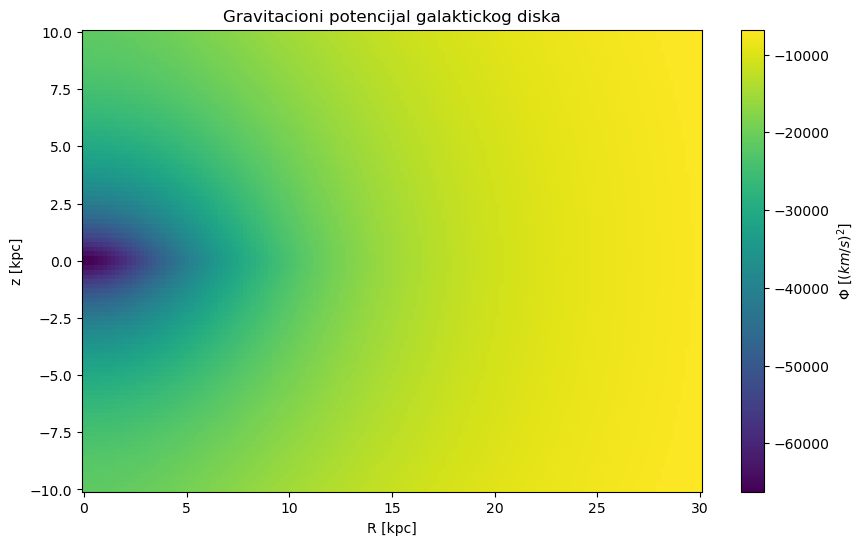

In [17]:
G = 4.30091e-6 

NR = 150
NZ = 100

R_grid = np.linspace(0, 30, NR)
z_grid = np.linspace(-10, 10, NZ)

RR, ZZ = np.meshgrid(R_grid, z_grid, indexing='ij')

rho = rho0 * np.exp(-RR / Rd) * np.exp(-np.abs(ZZ) / zd)

Phi = solve_poisson(rho, R_grid, z_grid, M_disk, G)

plt.figure(figsize=(10, 6))

plt.pcolormesh(RR, ZZ, Phi, shading='auto', cmap='viridis')
plt.colorbar(label=r'$\Phi$ [$(km/s)^2$]')

plt.xlabel('R [kpc]')
plt.ylabel('z [kpc]')
plt.title('Gravitacioni potencijal galaktickog diska')

plt.show()

#### Gravitacioni potencijal eksponencijalnog galaktickog diska određen je numerickim resavanjem Poasonove jednacine u cilindricnim koordinatama. Koriscena je metoda konacnih razlika na dvodimenzionalnoj mrezi od 150 × 100 tacaka, u oblasti 0 <= R <= 30 kpc i -10 <= z <= 10 kpc.

Ako znamo potencijal, brzinu rotacije možemo odrediti koristeći izraz:
$$ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $$

##### <font color="green">6. Koristeći prethodni izraz, prikazati rotacionu krivu. </font>

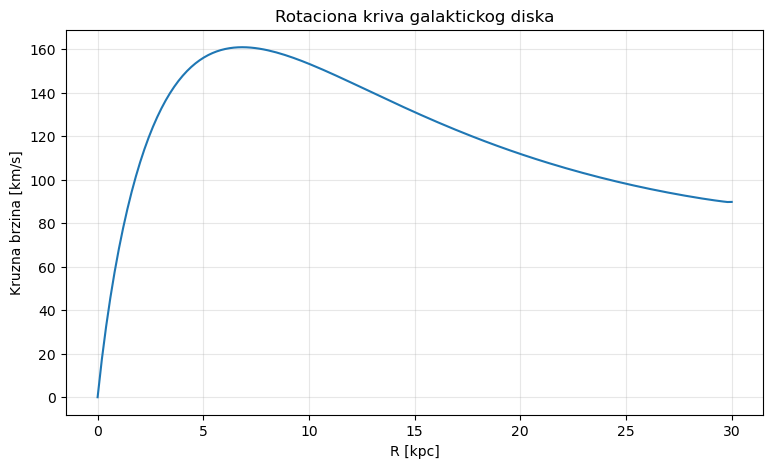

Maksimalna brzina: 160.96253621747266 km/s
Radijus maksimuma: 6.845637583892617 kpc
Broj negativnih vc^2: 0


In [18]:
Phi_ravan = (Phi[:, 49] + Phi[:, 50]) / 2

dPhi_dR = np.gradient(Phi_ravan, R_grid)

vc2 = R_grid * dPhi_dR
vc = np.sqrt(np.maximum(vc2, 0))

plt.figure(figsize=(9, 5))
plt.plot(R_grid, vc)

plt.xlabel('R [kpc]')
plt.ylabel('Kruzna brzina [km/s]')
plt.title('Rotaciona kriva galaktickog diska')
plt.grid(alpha=0.3)

plt.show()

print("Maksimalna brzina:", np.max(vc[:-1]), "km/s")
print("Radijus maksimuma:", R_grid[np.argmax(vc[:-1])], "kpc")
print("Broj negativnih vc^2:", np.sum(vc2 < 0))

#### Sa grafika se vidi da kruzna brzina u pocetku raste sa udaljenoscu od centra Galaksije i dostize maksimum od oko 160 km/s na priblizno 7 kpc. Nakon toga brzina postepeno opada i na 30 kpc iznosi oko 90 km/s. Za razliku od posmatranih rotacionih krivih spiralnih galaksija, koje su uglavnom priblizno ravne na velikim udaljenostima, nasa kriva opada jer model ne ukljucuje tamnu materiju.

##### <font color="green">7. Odrediti brzinu Sunca iz ove rotacione krive i uporediti sa prihvaćenom vrednošću. </font> 

In [19]:
R_sunce = 8.2  

v_sunce = np.interp(R_sunce, R_grid, vc)

v_prihvaceno = 230  

print("Brzina Sunca iz modela:", v_sunce, "km/s")
print("Prihvacena vrednost:", v_prihvaceno, "km/s")

odstupanje = abs(v_sunce - v_prihvaceno) / v_prihvaceno * 100

print("Relativno odstupanje:", odstupanje, "%")

Brzina Sunca iz modela: 159.2101486652427 km/s
Prihvacena vrednost: 230 km/s
Relativno odstupanje: 30.77819623250317 %


#### Iz dobijene rotacione krive odredjena je kruzna brzina na udaljenosti Sunca od galaktickog centra, koju smo uzeli da iznosi 8.2 kpc. Dobijena brzina je priblizno 159 km/s, sto je oko 31% manje od prihvacene vrednosti od priblizno 230 km/s. Ova razlika je ocekivana jer nas model ukljucuje samo zvezdani disk, dok u stvarnosti na gravitacioni potencijal Galaksije uticu i druge komponente.

##### <font color="green">8. Kako se menja rotaciona kriva ako je ukupna masa diska dva puta veća, z nepromenjene vrednosti $R_d$ i $z_d$. </font> 

#### Ako udvostrucimo ukupnu masu diska, a parametri Rd i zd ostanu nepromenjeni, gustina mase i gravitacioni potencijal ce se udvostruciti. Posto kruzna brzina zavisi od kvadratnog korena gradijenta potencijala, nova brzina ce biti koren iz 2 puta veca, odnosno povecace se za oko 41,4%. To znaci da ce rotaciona kriva zadrzati isti oblik i polozaj maksimuma, ali ce sve vrednosti brzine biti vece.